## MiniProject IDS
### Network Intrusion Detection System using the UNSW-NB15 dataset 

## Part A
### The problem and the data

Every day, a large number of network requests and flows enter organizations. To be able to understand and react to the different types of network traffic, machine learning can be used. One way to do this is by creating an Intrusion Detection System (IDS) that can classify network flows as either malicious or benign. However, to train such a system, we need a large amount of labeled data, which can be difficult to obtain.

A machine-learning-based IDS can be used in companies and could assist Security Operations Centre (SOC) analysts and network administrators in detecting potential cyberattacks and malicious activity and potentially blocking harmful requests before they enter the system.

However, false alerts in an intrusion detection system can be costly, as security analysts monitoring these alerts need to investigate and determine whether they are actual attacks or not. Too many false alerts can lead to alert fatigue, where analysts become overwhelmed by the number of warnings. This can reduce the effectiveness of the system, as frequent false alerts can cause people to lose trust in it and potentially overlook real attacks. 


In [78]:
# Run in your terminal once: pip install -r requirements_ids.txt
from pathlib import Path
import warnings, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, precision_score,
                             average_precision_score, confusion_matrix)
from sklearn.base import clone
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
START = time.perf_counter()
DATA_DIR = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
SAMPLE_SIZE = None  # Set to None to use all available rows
print('Data directory:', DATA_DIR.resolve())

Data directory: /Users/nishantgandhi/Library/CloudStorage/OneDrive-LuleåUniversityofTechnology/D7084E AI For Cybersecurity XAI/MiniProject/IntrusionDetectionSystem_MiniProject/data


### A1. Load and clean the CSV files

In [79]:
files = [DATA_DIR / "UNSW_NB15_training-set.csv",
         DATA_DIR / "UNSW_NB15_testing-set.csv"]

frames = []
for path in files:
    try:
        part = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        part = pd.read_csv(path, encoding="latin1", low_memory=False)
    part.columns = part.columns.str.strip().str.lower()
    frames.append(part)

df = pd.concat(frames, ignore_index=True).drop(columns="id", errors="ignore")
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().reset_index(drop=True)
df["label"] = pd.to_numeric(df["label"], errors="raise")
assert df["label"].isin([0, 1]).all(), "Unexpected target labels"
df["label"] = df["label"].astype(int)
df["attack_cat"] = df["attack_cat"].astype("string").str.strip().fillna("Unknown")

categorical = [c for c in ["proto", "service", "state"] if c in df]
for c in categorical:
    df[c] = df[c].astype("string").str.strip().fillna("Unknown")
for c in df.columns.difference(categorical + ["attack_cat", "label"]):
    df[c] = pd.to_numeric(df[c], errors="coerce")

# A small, stratified sample makes the presentation demo faster.
if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df, _ = train_test_split(df, train_size=SAMPLE_SIZE,
                             stratify=df["label"], random_state=SEED)
    df = df.reset_index(drop=True)

print("Rows:", len(df))
print("Input features:", len(df.columns) - 2)
print("Class counts:\n", df["label"].value_counts().sort_index())
print("Class percentages:\n", (100 * df["label"].value_counts(normalize=True)).round(2))
print("Attack categories:\n", df["attack_cat"].value_counts())
print("Missing feature values:", df.drop(columns=["label", "attack_cat"]).isna().sum().sum())

Rows: 162745
Input features: 42
Class counts:
 label
0    85722
1    77023
Name: count, dtype: int64
Class percentages:
 label
0    52.67
1    47.33
Name: proportion, dtype: float64
Attack categories:
 attack_cat
Normal            85722
Exploits          27434
Fuzzers           20960
Reconnaissance     9991
Generic            7599
DoS                5500
Analysis           2032
Backdoor           1880
Shellcode          1456
Worms               171
Name: count, dtype: Int64
Missing feature values: 0


### A2. Class balance and 60/20/20 split

Use 60% training, 20% validation, and 20% held-out testing, stratified by the binary label. Model choice is made on validation only. The test split is reserved until the final cell.

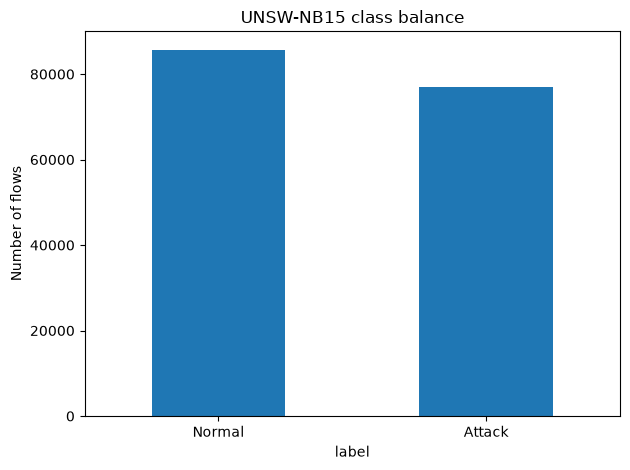

Train / validation / test: 97647 32549 32549


In [80]:
df["label"].map({0: "Normal", 1: "Attack"}).value_counts().reindex(["Normal", "Attack"]).plot.bar()
plt.title("UNSW-NB15 class balance")
plt.ylabel("Number of flows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

X = df.drop(columns=["label", "attack_cat"])
y = df["label"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))

## Part B — Supervised models

In [81]:
numeric = X.select_dtypes(include="number").columns.tolist()
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([
        ("missing", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

# Candidate settings are compared on validation data in section B1.
model_templates = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("scale", StandardScaler(with_mean=False)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocess),
        ("clf", DecisionTreeClassifier(random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_jobs=-1, random_state=SEED))
    ])
}

parameter_candidates = {
    "Logistic Regression": [{"clf__C": value} for value in [0.1, 1.0, 10.0]],
    "Decision Tree": [{"clf__max_depth": value} for value in [5, 10, None]],
    "Random Forest": [
        {"clf__n_estimators": n_estimators, "clf__max_depth": max_depth}
        for n_estimators in [100, 200]
        for max_depth in [10, None]
    ]
}

def scores(y_true, predicted, probability):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, predicted),
            "Macro-F1": f1_score(y_true, predicted, average="macro", zero_division=0),
            "Attack recall": recall_score(y_true, predicted, zero_division=0),
            "PR-AUC (AP)": average_precision_score(y_true, probability),
            "FAR": fp / (fp + tn) if fp + tn else 0.0}

majority = int(y_train.mode()[0])
def baseline(y_true):
    pred = np.full(len(y_true), majority)
    return scores(y_true, pred, pred.astype(float))

print("Majority class:", majority)
print("Training baseline accuracy:", round(baseline(y_train)["Accuracy"], 4))
print("Training baseline attack recall:", round(baseline(y_train)["Attack recall"], 4))

Majority class: 0
Training baseline accuracy: 0.5267
Training baseline attack recall: 0.0


### B1. Train models and compare on validation

All preprocessing is learned using **training data only**. Validation scores determine which model is selected. A higher macro-F1 is better.

In [82]:
validation = {"Majority baseline": baseline(y_val)}
models = {}
selected_settings = {}
tuning_rows = []

for name, template in model_templates.items():
    best_score = -1.0
    best_model = None
    best_metrics = None
    best_params = None

    for params in parameter_candidates[name]:
        candidate = clone(template).set_params(**params)
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_val)
        probability = candidate.predict_proba(X_val)[:, 1]
        metrics = scores(y_val, prediction, probability)
        tuning_rows.append({"Model": name, "Settings": str(params), **metrics})

        if metrics["Macro-F1"] > best_score:
            best_score = metrics["Macro-F1"]
            best_model = candidate
            best_metrics = metrics
            best_params = params

    models[name] = best_model
    validation[name] = best_metrics
    selected_settings[name] = best_params

print("Validation candidate settings:")
display(pd.DataFrame(tuning_rows).round(4))

validation_table = pd.DataFrame(validation).T.round(4)
print("Best validation result for each model:")
display(validation_table)
print("Selected settings:", selected_settings)

best_name = validation_table.drop(index="Majority baseline")["Macro-F1"].idxmax()
print("Selected model (validation macro-F1):", best_name)

Validation candidate settings:


,Model,Settings,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,Logistic Regression,{'clf__C': 0.1},0.8554,0.8553,0.9377,0.9460,0.2184
1,Logistic Regression,{'clf__C': 1.0},0.8581,0.8580,0.9356,0.9477,0.2116
2,Logistic Regression,{'clf__C': 10.0},0.8605,0.8604,0.9351,0.9484,0.2066
3,Decision Tree,{'clf__max_depth': 5},0.8637,0.8625,0.8129,0.9357,0.0906
4,Decision Tree,{'clf__max_depth': 10},0.9024,0.9018,0.8696,0.9667,0.0681
5,Decision Tree,{'clf__max_depth': None},0.8996,0.8992,0.8909,0.8506,0.0926
6,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': 10}",0.9047,0.9046,0.9250,0.9716,0.1135
7,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': N...",0.9198,0.9195,0.9104,0.9787,0.0717
8,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': 10}",0.9041,0.9040,0.9244,0.9717,0.1143
9,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': N...",0.9205,0.9202,0.9099,0.9790,0.0700


Best validation result for each model:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.5267,0.3450,0.0000,0.4733,0.0000
Logistic Regression,0.8605,0.8604,0.9351,0.9484,0.2066
Decision Tree,0.9024,0.9018,0.8696,0.9667,0.0681
Random Forest,0.9205,0.9202,0.9099,0.9790,0.0700


Selected settings: {'Logistic Regression': {'clf__C': 10.0}, 'Decision Tree': {'clf__max_depth': 10}, 'Random Forest': {'clf__n_estimators': 200, 'clf__max_depth': None}}
Selected model (validation macro-F1): Random Forest


### C1. Train black box on 5-10% labels

we investigate whether a Random Forest intrusion detector can learn effectively using only 10% of the training labels.

We compare three approaches:

1. Full supervised model: Random Forest trained using 100% of the training labels (from Part B).
2. Limited-label model: Random Forest trained using only 10% of the training labels.
3. Semi-supervised model: Random Forest trained using the 10% labelled data plus pseudo-labelled examples from the remaining 90%.

We evaluate the models using the same validation data and metrics from Part B.

In [83]:
# Keep only 10% of training records with their labels.
# The remaining 90% will be treated as unlabelled.
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train, y_train,train_size=0.10,
    stratify=y_train,random_state=SEED)

print("Total training records:", len(X_train))
print("Labelled records:", len(X_labeled))
print("Unlabelled records:", len(X_unlabeled))

# Create a fresh Random Forest 
rf_small = clone(models["Random Forest"])

# Train using only the 10% labelled records.
rf_small.fit(X_labeled, y_labeled)

# Evaluate on the same validation set from Part B.
pred_small = rf_small.predict(X_val)
prob_small = rf_small.predict_proba(X_val)[:, 1]

small_results = scores(y_val, pred_small, prob_small)

print("Random Forest trained with 10% labels:")
display(pd.DataFrame([small_results]).round(4))

Total training records: 97647
Labelled records: 9764
Unlabelled records: 87883
Random Forest trained with 10% labels:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.9064,0.9063,0.9148,0.9734,0.1011


### C2. Semi-supervised learning using pseudo-labelling

The limited-label Random Forest predicts labels for the remaining training records. We compare confidence cutoffs of 0.80, 0.90, and 0.95, selecting the cutoff with the highest validation Macro-F1. Validation labels are used only to choose this cutoff; pseudo-labels are generated only for unlabelled training features.

In [84]:
# Predict probabilities for the unlabelled training records only.
probs = rf_small.predict_proba(X_unlabeled)
confidence = probs.max(axis=1)
pseudo_labels = rf_small.classes_[probs.argmax(axis=1)]

confidence_thresholds = [0.80, 0.90, 0.95]
semi_results_by_threshold = {}
semi_models_by_threshold = {}
pseudo_counts = {}

for threshold in confidence_thresholds:
    selected = confidence >= threshold
    X_combined = pd.concat([X_labeled, X_unlabeled.loc[selected]])
    y_combined = pd.concat([
        y_labeled,
        pd.Series(pseudo_labels[selected], index=X_unlabeled.index[selected])
    ])

    candidate = clone(models["Random Forest"])
    candidate.fit(X_combined, y_combined)
    prediction = candidate.predict(X_val)
    probability = candidate.predict_proba(X_val)[:, 1]

    semi_results_by_threshold[threshold] = scores(y_val, prediction, probability)
    semi_models_by_threshold[threshold] = candidate
    pseudo_counts[threshold] = int(selected.sum())

threshold_table = pd.DataFrame({
    threshold: semi_results_by_threshold[threshold]
    for threshold in confidence_thresholds
}).T
threshold_table.index.name = "Confidence threshold"
print("Validation results by pseudo-label confidence threshold:")
display(threshold_table.round(4))

best_threshold = max(
    confidence_thresholds,
    key=lambda threshold: semi_results_by_threshold[threshold]["Macro-F1"]
)
semi_results = semi_results_by_threshold[best_threshold]
rf_semi = semi_models_by_threshold[best_threshold]
print("Selected confidence threshold:", best_threshold)
print("Pseudo-labelled training records:", pseudo_counts[best_threshold])
print("Random Forest with selected pseudo-labelling threshold:")
display(pd.DataFrame([semi_results]).round(4))

Validation results by pseudo-label confidence threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Confidence threshold,,,,,
0.80,0.9040,0.9039,0.9287,0.9708,0.1183
0.90,0.9046,0.9045,0.9232,0.9729,0.1122
0.95,0.9046,0.9045,0.9159,0.9729,0.1056


Selected confidence threshold: 0.9
Pseudo-labelled training records: 59988
Random Forest with selected pseudo-labelling threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.9046,0.9045,0.9232,0.9729,0.1122


### C3. Results and comparison

In [85]:
# Use the full-data Random Forest results from Part B.
comparison = pd.DataFrame({
    "RF - 100% labels": validation["Random Forest"],
    "RF - 10% labels": small_results,
    "RF - Pseudo-labelling": semi_results
}).T

print("Part C - Validation results:")
display(comparison.round(4))

gain = semi_results["Macro-F1"] - small_results["Macro-F1"]
print(f"\nMacro-F1 change with pseudo-labelling: {gain:+.6f}")

if abs(gain) < 0.001:
    print("Pseudo-labelling made no meaningful Macro-F1 change (< 0.001).")
elif gain > 0:
    print("Pseudo-labelling improved Macro-F1.")
else:
    print("Pseudo-labelling reduced Macro-F1.")

Part C - Validation results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
RF - 100% labels,0.9205,0.9202,0.9099,0.9790,0.0700
RF - 10% labels,0.9064,0.9063,0.9148,0.9734,0.1011
RF - Pseudo-labelling,0.9046,0.9045,0.9232,0.9729,0.1122



Macro-F1 change with pseudo-labelling: -0.001780
Pseudo-labelling reduced Macro-F1.


## Final evaluation — held-out test

This cell reports test metrics only after all validation-based model and threshold choices are complete. Keep the evaluation at the end of the notebook as Parts D–G are added.

In [86]:
# Final held-out test evaluation for Parts A-C.
# NOTE Keep this cell last when adding later project parts; run it only after all validation-based choices.
final_models = {
    **models,
    "Random Forest - 10% labels": rf_small,
    "Random Forest - pseudo-labels": rf_semi
}
test_results = {"Majority baseline": baseline(y_test)}
for name, model in final_models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    test_results[name] = scores(y_test, prediction, probability)

test_table = pd.DataFrame(test_results).T.round(4)
print("Final held-out test results:")
display(test_table)
print("Validation-selected model:", best_name)
print("Selected model settings:", selected_settings[best_name])
print("Selected pseudo-label threshold:", best_threshold)

Final held-out test results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.5267,0.3450,0.0000,0.4733,0.0000
Logistic Regression,0.8625,0.8624,0.9381,0.9499,0.2054
Decision Tree,0.9043,0.9037,0.8724,0.9683,0.0671
Random Forest,0.9175,0.9173,0.9099,0.9789,0.0756
Random Forest - 10% labels,0.9080,0.9078,0.9160,0.9742,0.0992
Random Forest - pseudo-labels,0.9060,0.9060,0.9236,0.9730,0.1097


Validation-selected model: Random Forest
Selected model settings: {'clf__n_estimators': 200, 'clf__max_depth': None}
Selected pseudo-label threshold: 0.9
